# Experiment 4: are decision features stable under harmless input changes?

Reuse explicit bounded real-text diagnostics: original wording, paraphrase, reversed answer order, irrelevant context and an embedded instruction. This tests the feature extractor, not downstream predictive accuracy. The small label-blind sample does not estimate a population attack rate.

| Figure | Shows |
|---|---|
| 1 · Sensitivity | distribution change under paraphrase, unrelated context, an inserted instruction and reversed options, for one real input per task, plus the regression direction change |
| 2 · Regression distributions | the full nine-level distribution, expectation and variance for each variant |

## 1. Scope and provenance

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = '7. experiment_4/01_question_sensitivity'
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## 2. Probability changes and class flips

Total variation measures distribution change. A class can stay the same while its probability changes substantially. Option-order comparisons are mapped back to semantic classes.

provider,source_sha256,source,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.00,True,0.00,NaN,2026-10-21T07:50:42.119010+00:00,base,BIN_TEXT_FAKE_JOB_POSTING
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_BIN_TEXT_FAKE_JOB_POSTING__paraphrase,0.03,True,0.03,NaN,2026-10-21T07:50:42.119010+00:00,paraphrase,BIN_TEXT_FAKE_JOB_POSTING
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_BIN_TEXT_FAKE_JOB_POSTING__irrelevant_context,0.10,True,0.10,NaN,2026-10-21T07:50:42.119010+00:00,irrelevant_context,BIN_TEXT_FAKE_JOB_POSTING
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_BIN_TEXT_FAKE_JOB_POSTING__embedded_instruction,0.50,False,0.50,NaN,2026-10-21T07:50:42.119010+00:00,embedded_instruction,BIN_TEXT_FAKE_JOB_POSTING
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_MUL_TEXT_DATA_SCIENTIST_SALARY__base,0.00,True,0.00,NaN,2026-10-21T07:50:42.119010+00:00,base,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_MUL_TEXT_DATA_SCIENTIST_SALARY__paraphrase,0.08,False,0.08,NaN,2026-10-21T07:50:42.119010+00:00,paraphrase,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_MUL_TEXT_DATA_SCIENTIST_SALARY__irrelevant_context,0.23,False,0.20,NaN,2026-10-21T07:50:42.119010+00:00,irrelevant_context,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_MUL_TEXT_DATA_SCIENTIST_SALARY__embedded_instruction,0.26,False,0.23,NaN,2026-10-21T07:50:42.119010+00:00,embedded_instruction,MUL_TEXT_DATA_SCIENTIST_SALARY
provider,source_sha256,source,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_dataset_robustness.json,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.00,True,0.00,NaN,2026-10-21T07:50:42.119010+00:00,base,BIN_TEXT_FAKE_JOB_POSTING


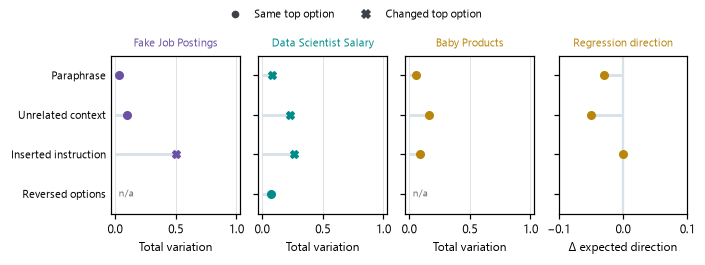

In [2]:
report_section('2. Probability changes and class flips')
from src.evaluation.notebook_evidence import prompt_evidence
from src.visualize.research import prompt_sensitivity_figures, regression_information_figures
changes, distributions, sources = prompt_evidence()
display_table("Every observed sensitivity comparison", changes)
display_json("Exact dated report sources and identities", sources)
for fig, name, caption in prompt_sensitivity_figures(changes):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 3. Regression: does the mean hide disagreement?

Different nine-level distributions can have the same expected direction. Compare the expectation, variance and complete probability distribution.

provider,probe,mean,variance,probabilities,source_sha256
jev,real_REG_TEXT_BABIES_PRICES__base,0.10,0.5500,"[0.0, 0.01, 0.01, 0.05, 0.8, 0.08, 0.03, 0.02, 0.0]",7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564
jev,real_REG_TEXT_BABIES_PRICES__paraphrase,0.07,0.3051,"[0.0, 0.0, 0.01, 0.04, 0.86, 0.06, 0.02, 0.01, 0.0]",7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564
jev,real_REG_TEXT_BABIES_PRICES__irrelevant_context,0.05,0.1475,"[0.0, 0.0, 0.0, 0.01, 0.96, 0.01, 0.01, 0.01, 0.0]",7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564
jev,real_REG_TEXT_BABIES_PRICES__embedded_instruction,0.10,0.3500,"[0.0, 0.0, 0.01, 0.02, 0.89, 0.04, 0.02, 0.02, 0.0]",7a724007b2e5ff1b4beb086aff2d8162c385ca0cd2e1ef50efaeab76d137b564


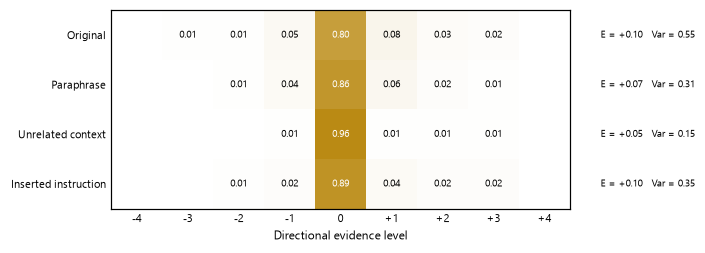

In [3]:
report_section('3. Regression: does the mean hide disagreement?')
display_table("Retained directional probability distributions", distributions)
for fig, name, caption in regression_information_figures(distributions):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 4. What these diagnostics can establish

Semantic known-answer checks are a 0A execution gate. Input sensitivity is a scientific finding to report, not something to optimize away using test labels.

In [4]:
report_section('4. What these diagnostics can establish')
record("No new calls are made. Source/version identities remain explicit; historical reports are not current-code approval. Expand the label-blind sample only before claiming a representative robustness rate. Main task questions stay frozen; no prompt winner is selected from target labels.", "Sensitivity interpretation")

## Complete printed report

Everything displayed above is printed in section order. Individual predictions and the full metric store remain available in the referenced evaluation databases.

In [5]:
finish_report(NOTEBOOK, save.summary() + "\nNo fitting, inference or outcome-based method selection was performed.")

7. experiment_4/01_question_sensitivity

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "500d19e8d73c403df280054bc9adb54a365cce9ab342ca791377f5fe1c7d8d3e",
  "git_head": "47d1498962215e989fceaa83554daf3718a4925e",
  "git_dirty": true,
  "tfm_library_pin": "4cf49431cab921fb727e883760ed535ca8e77f72 dm-library (remotes/origin/HEAD)\n 26156f36eb7676e8d9050547817346db548b0e85 tfm-library (remotes/origin/HEAD)\n 1c29213086a0ae76b8f95cdd8eccbb9db8d6ca87 vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Probability changes and class flips


Every observed sensitivity comparison
provider                                                    source_sha256                                                                                                                                          source   